# 02. Análisis exploratorio y estadística descriptiva


### Objetivo
Documentar propiedades a partir de tablas consolidadas.



## Preparación del entorno y lectura reproducible
El notebook busca el directorio `data/processed` generado en la etapa anterior, en su ausencia, permite ejecutarse con los dataset colocados junto al notebook o dentro de una carpeta indicada. No requiere los archivos originales.

Muestra cantidad de registros y cantidad de variables en los dataset trabajados.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

FILES = [
    "column_quality.csv", "genre_frequency.csv", "key_checks.csv",
    "movie_genres.csv", "movies_consolidated.csv", "movies_without_ratings.csv",
    "movies_without_tags.csv", "post_validation.csv", "quality_overview.csv",
    "rating_aggregates_by_movie.csv", "rating_distribution.csv",
    "referential_integrity.csv", "tag_aggregates_by_movie.csv",
    "title_duplicates_exact.csv"
]


DATA_DIR_OVERRIDE = None
cwd = Path.cwd().resolve()
candidates = ([Path(DATA_DIR_OVERRIDE).expanduser().resolve()] if DATA_DIR_OVERRIDE else []) + [
    p / "data" / "processed" for p in (cwd, *cwd.parents)
] + [cwd, cwd / "data" / "processed", cwd / "archivos", Path("/mnt/data")]
DATA_DIR = next((p for p in candidates if p.is_dir() and all((p / f).is_file() for f in FILES)), None)
if DATA_DIR is None:
    raise FileNotFoundError("No se localizaron los dataset. Configura DATA_DIR_OVERRIDE con la carpeta donde se encuentran.")

tables = {Path(f).stem: pd.read_csv(DATA_DIR / f, low_memory=False) for f in FILES}
movies = tables["movies_consolidated"]
movie_genres = tables["movie_genres"]
rating_dist = tables["rating_distribution"].copy()
print("Directorio de datos:", DATA_DIR)
#print("Bases cargadas:", len(tables))
display(pd.DataFrame([{"archivo": f"{k}.csv", "registros": len(v), "variables": v.shape[1]} for k,v in tables.items()]))
assert len(tables) == 14
assert movies["movieId"].is_unique, "movies_consolidated debe tener una película por fila"
assert not movie_genres.duplicated(["movieId", "genre"]).any(), "Duplicación película-género"

Directorio de datos: C:\Users\igpea\OneDrive\Documents\Diplomado\Proyecto_Integrador_M1\data\processed


,archivo,registros,variables
0,column_quality.csv,14,7
1,genre_frequency.csv,20,3
2,key_checks.csv,4,5
3,movie_genres.csv,154170,2
4,movies_consolidated.csv,87585,20
5,movies_without_ratings.csv,3153,3
6,movies_without_tags.csv,36262,3
7,post_validation.csv,6,2
8,quality_overview.csv,4,8
9,rating_aggregates_by_movie.csv,84432,7


## 1. Entendimiento de los datos y registros relevantes
Las películas son entidades del catálogo, las puntuaciones son evaluaciones explícitas de usuarios y las etiquetas describen aportaciones textuales. Los identificadores de MovieLens, IMDb y TMDb son **identificadores **, no magnitudes, se consideran cualitativa nominal. `rating_count` mide cuántas evaluaciones recibió una película; `rating_mean` sólo existe si recibió al menos una. La ausencia de evaluaciones o etiquetas no equivale a una puntuación de cero ni a una opinión negativa.


In [3]:
# 2. COBERTURA, INTEGRIDAD Y REPRESENTATIVIDAD
q = tables["quality_overview"]
display(q)
for col in ["has_ratings", "has_tags", "has_imdb_id", "has_tmdb_id"]:
    if col in movies.columns:
        print(f"{col}: {movies[col].astype('boolean').mean()*100:.2f}% de las películas")
print("Calificaciones totales (tabla de frecuencias):", int(rating_dist["frequency"].sum()))
print("Películas distintas:", movies["movieId"].nunique())
print("Películas sin calificaciones:", int((movies["rating_count"] == 0).sum()))
print("Películas sin etiquetas:", int((movies["tag_application_count"] == 0).sum()))
print("Géneros distintos:", movie_genres["genre"].nunique())
print("Media global de evaluaciones por evento:",
      np.average(rating_dist["rating"], weights=rating_dist["frequency"]))
print("Media no ponderada de medias por película:", movies["rating_mean"].mean())
print("Las dos medias anteriores responden preguntas distintas: evento vs. película.")

ranking = movies.loc[movies["rating_count"] >= 100, ["movieId", "title_clean", "rating_count", "rating_mean", "tag_application_count"]]
print("Películas con mayor número de evaluaciones (sin inferir calidad):")
display(ranking.sort_values("rating_count", ascending=False).head(10))
print("Películas con media más elevada, restringiendo a >=100 evaluaciones:")
display(ranking.sort_values(["rating_mean", "rating_count"], ascending=False).head(10))

,dataset,records,columns,distinct_values_sum,full_row_duplicates,null_cells,completeness_pct,memory_mb
0,movies,87585,3,176765,0,0,100.0000,11.9166
1,ratings,32000204,4,26261913,0,0,100.0000,610.3556
2,tags,2000072,4,1499400,0,17,99.9998,145.2141
3,links,87585,3,262595,0,124,99.9528,1.8377


has_ratings: 96.40% de las películas
has_tags: 58.60% de las películas
has_imdb_id: 100.00% de las películas
has_tmdb_id: 99.86% de las películas
Calificaciones totales (tabla de frecuencias): 32000204
Películas distintas: 87585
Películas sin calificaciones: 3153
Películas sin etiquetas: 36262
Géneros distintos: 20
Media global de evaluaciones por evento: 3.5403956487277393
Media no ponderada de medias por película: 3.005082385038019
Las dos medias anteriores responden preguntas distintas: evento vs. película.
Películas con mayor número de evaluaciones (sin inferir calidad):


,movieId,title_clean,rating_count,rating_mean,tag_application_count
314,318,"Shawshank Redemption, The",102929,4.4046,4892
351,356,Forrest Gump,100296,4.0527,3581
292,296,Pulp Fiction,98409,4.1970,6697
2480,2571,"Matrix, The",93808,4.1564,5722
585,593,"Silence of the Lambs, The",90330,4.1484,3469
257,260,Star Wars: Episode IV - A New Hope,85010,4.0998,6519
2867,2959,Fight Club,77332,4.2288,5532
475,480,Jurassic Park,75233,3.6986,1510
522,527,Schindler's List,73849,4.2370,2059
4888,4993,"Lord of the Rings: The Fellowship of the Ring,...",73122,4.0921,2550


Películas con media más elevada, restringiendo a >=100 evaluaciones:


,movieId,title_clean,rating_count,rating_mean,tag_application_count
46252,171011,Planet Earth II,1956,4.4468,96
40985,159817,Planet Earth,2948,4.4444,103
46103,170705,Band of Brothers,2811,4.4265,234
314,318,"Shawshank Redemption, The",102929,4.4046,4892
46487,171495,Cosmos,615,4.3301,167
840,858,"Godfather, The",66440,4.3170,2310
61090,202439,Parasite,11670,4.3123,3052
50126,179135,Blue Planet II,1163,4.3001,74
59131,198185,Twin Peaks,1140,4.2987,146
68471,220528,Twelve Angry Men,449,4.2862,8


### Sesgos y límites de inferencia
- **Autoselección:** quienes califican películas no constituyen una muestra aleatoria de todas las personas ni de todos los espectadores.
- **Popularidad y supervivencia de actividad:** las películas con mayor exposición acumulan más observaciones; medias de títulos con pocos votos son menos estables.
- **Sesgo de cobertura:** los títulos sin evaluaciones participan en el catálogo, pero no en la distribución de notas observadas.
- **Granularidad y ponderación:** una media de medias por película pondera todos los títulos igual; la media global de evaluaciones pondera por número de eventos.
- **Géneros multilabel:** una película puede pertenecer a varios géneros; sumar las frecuencias de géneros no produce el total de películas.
- **No causalidad:** una correlación entre actividad y puntuación no demuestra que una variable genere la otra.

## 2. Clasificación de variables, escalas de medición y comparaciones permitidas

Se diferencian **tipo estadístico** y **escala**. Para una nominal son válidas igualdad, diferencias de proporciones y moda, no promedios. Una ordinal añade orden, mediana y cuantiles cuando se trata de puntuaciones ordenadas. La escala de intervalo permite diferencias numéricas pero no interpretaciones de tipo “el doble”; razón añade un cero absoluto y cocientes interpretables. Las puntuaciones `rating` son **ordinales discretas** en sentido estricto; analizar sus medias como *intervalo aproximado* constituye un supuesto práctico explícito. Una marca booleana es nominal dicotómica aunque se almacene como `bool`. Los identificadores numéricos siguen siendo nominales.

La desviación estándar, CV, asimetría, curtosis y Pearson no se aplican a IDs, textos ni indicadores categóricos. En las variables de conteo, un cero sí indica ausencia de actividad; en las medias de puntuación, cero no es un valor admisible en la escala.

In [2]:
# 3. DICCIONARIO ESTADÍSTICO DOCUMENTADO
metadata = {
"movieId": ("Cualitativa nominal", "Nominal", "ID de película", "Igualdad, unión, conteos de películas"),
"title_clean": ("Cualitativa nominal", "Nominal", "Título limpio", "Frecuencias y títulos duplicados"),
"title": ("Cualitativa nominal", "Nominal", "Título", "Frecuencias y títulos duplicados"),
"genres": ("Cualitativa nominal multilabel", "Nominal", "Lista de géneros", "Pertenencia y proporciones por categoría"),
"genres_original": ("Cualitativa nominal multilabel", "Nominal", "Géneros originales", "Comparación de categorías"),
"year": ("Cuantitativa discreta derivada", "Razón", "Año de estreno", "Tendencias temporales y agrupación por periodos"),
"genre": ("Cualitativa nominal", "Nominal", "Género individual", "Frecuencias y cobertura por género"),
"imdbId": ("Cualitativa nominal", "Nominal", "ID IMDb", "Unicidad y enlaces"),
"tmdbId": ("Cualitativa nominal", "Nominal", "ID TMDb", "Unicidad y enlaces"),
"rating": ("Cualitativa ordinal (valores discretos)", "Ordinal; intervalo aproximado para medias", "Puntos (0.5–5)", "Orden, frecuencias, cuartiles; media bajo supuesto"),
"rating_count": ("Cuantitativa discreta", "Razón", "Número de evaluaciones", "Diferencias, cocientes, cuantiles, dispersión"),
"rating_users": ("Cuantitativa discreta", "Razón", "Usuarios que evaluaron", "Diferencias, cocientes, dispersión"),
"rating_mean": ("Cuantitativa continua derivada", "Intervalo aproximado", "Puntos por película", "Diferencias; media/correlación con cautela"),
"rating_std": ("Cuantitativa continua derivada", "Razón (magnitud de dispersión)", "Puntos por película", "Comparación de dispersión; no aplica con n<2"),
"rating_min": ("Cuantitativa derivada discreta", "Ordinal", "Puntos", "Orden y comparación de extremos"),
"rating_max": ("Cuantitativa derivada discreta", "Ordinal", "Puntos", "Orden y comparación de extremos"),
"tag_application_count": ("Cuantitativa discreta", "Razón", "Etiquetas por película", "Frecuencias, cocientes y dispersión"),
"non_null_tag_count": ("Cuantitativa discreta", "Razón", "Etiquetas con texto", "Frecuencias, cocientes y dispersión"),
"distinct_tags": ("Cuantitativa discreta", "Razón", "Etiquetas únicas por película", "Conteos y comparación de diversidad textual"),
"tag_users": ("Cuantitativa discreta", "Razón", "Usuarios con etiquetas", "Conteos y comparaciones"),
"has_ratings": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Proporciones y tablas cruzadas"),
"has_tags": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Proporciones y tablas cruzadas"),
"has_imdb_id": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Cobertura de identificadores"),
"has_tmdb_id": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Cobertura de identificadores"),
}
dictionary = pd.DataFrame([{
    "variable": c, "tipo_estadístico": metadata.get(c, ("Revisar", "Revisar", "", ""))[0],
    "escala": metadata.get(c, ("Revisar", "Revisar", "", ""))[1],
    "unidad/significado": metadata.get(c, ("", "", "Revisar", ""))[2],
    "comparaciones_permitidas": metadata.get(c, ("", "", "", "Revisar"))[3],
    "tipo_python": str(movies[c].dtype)
} for c in movies.columns])
display(dictionary)
assert not dictionary["tipo_estadístico"].eq("Revisar").any(), "Clasifica cualquier columna nueva antes de analizarla"

,variable,tipo_estadístico,escala,unidad/significado,comparaciones_permitidas,tipo_python
0,movieId,Cualitativa nominal,Nominal,ID de película,"Igualdad, unión, conteos de películas",int64
1,title_clean,Cualitativa nominal,Nominal,Título limpio,Frecuencias y títulos duplicados,object
2,year,Cuantitativa discreta derivada,Razón,Año de estreno,Tendencias temporales y agrupación por periodos,float64
3,genres,Cualitativa nominal multilabel,Nominal,Lista de géneros,Pertenencia y proporciones por categoría,object
4,imdbId,Cualitativa nominal,Nominal,ID IMDb,Unicidad y enlaces,int64
5,tmdbId,Cualitativa nominal,Nominal,ID TMDb,Unicidad y enlaces,float64
6,rating_count,Cuantitativa discreta,Razón,Número de evaluaciones,"Diferencias, cocientes, cuantiles, dispersión",int64
7,rating_mean,Cuantitativa continua derivada,Intervalo aproximado,Puntos por película,Diferencias; media/correlación con cautela,float64
8,rating_std,Cuantitativa continua derivada,Razón (magnitud de dispersión),Puntos por película,Comparación de dispersión; no aplica con n<2,float64
9,rating_min,Cuantitativa derivada discreta,Ordinal,Puntos,Orden y comparación de extremos,float64


## 3. Distribuciones de frecuencia
Para variables nominales se presentan frecuencias absolutas y relativas. Para conteos cuantitativos se incluyen intervalos interpretables definidos de antemano.

In [6]:
# 4. FRECUENCIAS CATEGÓRICAS Y ORDINALES
print("Distribución completa de calificaciones por evento:")
rd = rating_dist.sort_values("rating").copy()
rd["porcentaje_recalculado"] = rd["frequency"] / rd["frequency"].sum() * 100
display(rd)
print("Frecuencia de géneros: una película puede aparecer en varios géneros")
g = movie_genres.groupby("genre", dropna=False)["movieId"].nunique().sort_values(ascending=False).rename("peliculas").reset_index()
g["porcentaje_catalogo"] = 100 * g["peliculas"] / movies["movieId"].nunique()
display(g)
for flag in ["has_ratings", "has_tags", "has_imdb_id", "has_tmdb_id"]:
    d = movies[flag].value_counts(dropna=False).rename_axis(flag).reset_index(name="frecuencia")
    d["porcentaje"] = 100 * d["frecuencia"] / len(movies)
    print(flag)
    display(d)

bins = [-0.1, 0, 1, 5, 20, 100, 1000, np.inf]
labels = ["0", "1", "2–5", "6–20", "21–100", "101–1000", ">1000"]
for field in ["rating_count", "tag_application_count"]:
    d = pd.cut(movies[field], bins=bins, labels=labels).value_counts(sort=False)
    display(pd.DataFrame({"variable": field, "intervalo": d.index.astype(str), "frecuencia": d.values,
                          "porcentaje": d.values / len(movies) * 100}))
print("La suma de porcentajes por género puede superar 100% por clasificación múltiple.")

Distribución completa de calificaciones por evento:


,rating,frequency,percentage,porcentaje_recalculado
0,0.5000,525132,1.6410,1.6410
1,1.0000,946675,2.9583,2.9583
2,1.5000,531063,1.6596,1.6596
3,2.0000,2028622,6.3394,6.3394
4,2.5000,1685386,5.2668,5.2668
5,3.0000,6054990,18.9217,18.9217
6,3.5000,4290105,13.4065,13.4065
7,4.0000,8367654,26.1488,26.1488
8,4.5000,2974000,9.2937,9.2937
9,5.0000,4596577,14.3642,14.3642


Frecuencia de géneros: una película puede aparecer en varios géneros


,genre,peliculas,porcentaje_catalogo
0,Drama,34175,39.0192
1,Comedy,23124,26.4018
2,Thriller,11823,13.4989
3,Romance,10369,11.8388
4,Action,9668,11.0384
5,Documentary,9363,10.6902
6,Horror,8654,9.8807
7,(no genres listed),7080,8.0836
8,Crime,6976,7.9648
9,Adventure,5402,6.1677


has_ratings


,has_ratings,frecuencia,porcentaje
0,True,84432,96.4001
1,False,3153,3.5999


... (5 outputs left out)

,has_tmdb_id,frecuencia,porcentaje
0,True,87461,99.8584
1,False,124,0.1416


,variable,intervalo,frecuencia,porcentaje
0,rating_count,0,3153,3.5999
1,rating_count,1,18607,21.2445
2,rating_count,2–5,25420,29.0232
3,rating_count,6–20,17547,20.0343
4,rating_count,21–100,10713,12.2315
5,rating_count,101–1000,7750,8.8485
6,rating_count,>1000,4395,5.0180


,variable,intervalo,frecuencia,porcentaje
0,tag_application_count,0,36262,41.4021
1,tag_application_count,1,7682,8.7709
2,tag_application_count,2–5,18056,20.6154
3,tag_application_count,6–20,14519,16.5770
4,tag_application_count,21–100,7193,8.2126
5,tag_application_count,101–1000,3630,4.1445
6,tag_application_count,>1000,243,0.2774


La suma de porcentajes por género puede superar 100% por clasificación múltiple.



### 4. ¿Cómo varían las calificaciones según la cantidad de calificaciones recibidas?

 Antes de relacionar comparar calificaciones entre géneros o épocas, describiremos  cuántas calificaciones recibe cada película mediante medidas de tendencia central, dispersión y sensibilidad (media recortada al 5%) y un histograma en escala logarítmica. Después examinamos cómo cambia la calificación promedio según ese número con un gráfico de dispersión. Los resultados justifican las decisiones metodológicas del resto del análisis: ponderar los promedios y fijar umbrales mínimos de calificaciones.

In [3]:
def trimmed_mean(x, proportion=0.05):
    v = np.sort(pd.to_numeric(pd.Series(x), errors="coerce").dropna().to_numpy(dtype=float))
    k = int(len(v) * proportion)
    return float(v[k: len(v)-k].mean()) if len(v) > 2*k else np.nan

def descriptive(x, name, cv=True):
    s = pd.to_numeric(pd.Series(x), errors="coerce").dropna()
    if s.empty: return {"variable": name, "n": 0}
    q1, q3 = s.quantile([0.25, 0.75]); mu = s.mean(); sd = s.std(ddof=1)
    modes = s.mode()
    return {"variable": name, "n": int(len(s)), "media": mu, "mediana": s.median(),
            "moda": modes.iloc[0] if len(modes) else np.nan,
            "modas_totales": len(modes), "varianza_muestral": s.var(ddof=1),
            "desviacion_muestral": sd, "q1": q1, "q3": q3, "IQR": q3-q1,
            "mínimo": s.min(), "máximo": s.max(),
            "CV_pct": 100*sd/mu if cv and mu>0 else np.nan,
            "media_recortada_5pct": trimmed_mean(s),
            "cambio_media_recorte_pct": 100*(trimmed_mean(s)-mu)/mu if mu != 0 else np.nan}

count_vars = ["rating_count"]
count_stats = pd.DataFrame([descriptive(movies[c],c) for c in count_vars])
t = count_stats.set_index("variable").T



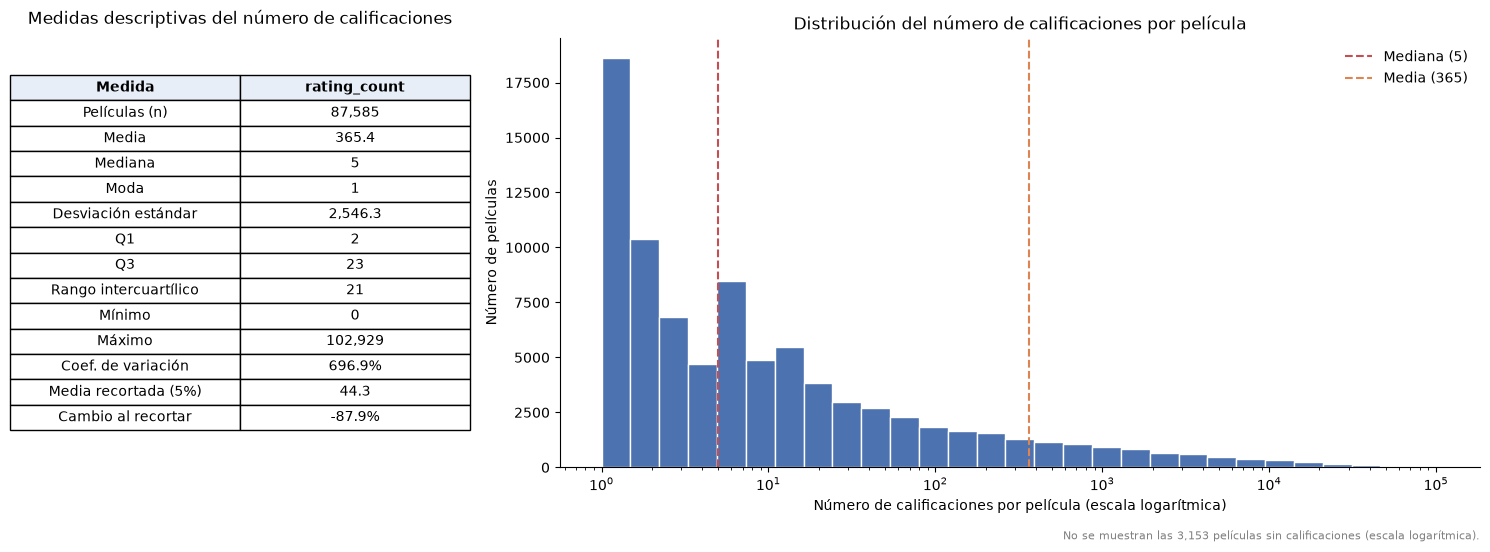

In [7]:
t.columns.name = None
t = count_stats.set_index("variable").T
t.columns.name = None

etiquetas = {
    "n": "Películas (n)",
    "media": "Media",
    "mediana": "Mediana",
    "moda": "Moda",
    "desviacion_muestral": "Desviación estándar",
    "q1": "Q1",
    "q3": "Q3",
    "IQR": "Rango intercuartílico",
    "mínimo": "Mínimo",
    "máximo": "Máximo",
    "CV_pct": "Coef. de variación",
    "media_recortada_5pct": "Media recortada (5%)",
    "cambio_media_recorte_pct": "Cambio al recortar",
}

def fmt(valor, pct=False):
    texto = f"{valor:,.0f}" if float(valor).is_integer() else f"{valor:,.1f}"
    return texto + ("%" if pct else "")

filas = [(etiquetas[m], fmt(t.loc[m, "rating_count"], pct=m.endswith("_pct"))) for m in etiquetas]

# ---------- Datos del histograma ----------
r = movies["rating_count"].fillna(0)   # usa el nombre que tenga esa tabla en tu notebook
r_pos = r[r > 0]                                    # el cero no existe en escala logarítmica
n_cero = int((r == 0).sum())

mediana = t.loc["mediana", "rating_count"]
media = t.loc["media", "rating_count"]

# ---------- Figura ----------
fig, (ax_tabla, ax_graf) = plt.subplots(
    1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 2]}
)

ax_tabla.axis("off")
tbl = ax_tabla.table(cellText=filas, colLabels=["Medida", "rating_count"],
                     cellLoc="center", loc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.5)
for (i, j), celda in tbl.get_celld().items():
    if i == 0:
        celda.set_text_props(weight="bold")
        celda.set_facecolor("#E8EEF7")
ax_tabla.set_title("Medidas descriptivas del número de calificaciones", pad=10)

bins = np.logspace(0, np.log10(r_pos.max()), 30)
ax_graf.hist(r_pos, bins=bins, color="#4C72B0", edgecolor="white")
ax_graf.set_xscale("log")
ax_graf.axvline(mediana, color="#C44E52", linestyle="--", label=f"Mediana ({mediana:,.0f})")
ax_graf.axvline(media, color="#DD8452", linestyle="--", label=f"Media ({media:,.0f})")
ax_graf.set_xlabel("Número de calificaciones por película (escala logarítmica)")
ax_graf.set_ylabel("Número de películas")
ax_graf.set_title("Distribución del número de calificaciones por película")
ax_graf.legend(frameon=False)
ax_graf.spines[["top", "right"]].set_visible(False)

fig.text(0.99, 0.01, f"No se muestran las {n_cero:,} películas sin calificaciones (escala logarítmica).",
         ha="right", fontsize=8, color="gray")

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Interpretación.** La gran mayoría de las películas recibe pocas calificaciones: la mediana es **5**, la moda es **1** y el 75% de las películas tiene **23 o menos** (Q3). En el otro extremo, unas pocas películas muy populares alcanzan decenas de miles de calificaciones, con un máximo de **102,929**. Por eso la distribución está fuertemente **sesgada hacia la derecha**.

Las medidas de la tabla confirman este patrón. La media (**365.4**) es 73 veces la mediana, y la desviación estándar (**2,546.3**) es casi siete veces la media, lo que se refleja en un coeficiente de variación cercano a **697%**. Al recortar el 5% de cada extremo, la media cae a **44.3**, un **88%** menos, lo que indica que unas pocas películas aportan la mayor parte del total de calificaciones. Por eso la mediana describe mejor a la película típica que la media.

Se utiliza una escala logarítmica en el eje X para poder visualizar en una misma gráfica tanto los rangos bajos como los altos, sin que los valores extremos aplasten al resto.

**Limitaciones.** El histograma solo muestra las películas con al menos una calificación (`rating_count > 0`): quedan fuera las **3,153 películas sin calificaciones** (3.6% del catálogo). 

### ¿Cómo cambia el promedio de una calificación según el número de cálificaciones que reciba?

Para describir qué calificaciones asignan los usuarios calculamos medidas de tendencia central y de dispersión sobre dos unidades de análisis distintas:

- **Por calificación individual** (32,000,204 calificaciones): cada calificación emitida es una observación. Las medidas se calculan con la frecuencia de cada valor de la escala, sin expandir los datos, por lo que las películas con más calificaciones pesan más en el resultado.
- **Por película** (películas con al menos una calificación): cada título aporta una observación, su calificación promedio, y todas pesan igual, tengan pocas o muchas calificaciones. Además, repetimos el cálculo restringiéndonos a las películas con **100 o más calificaciones**, para ver **cómo cambia el promedio y su dispersión cuando la calificación de una película se apoya en más datos**.

La escala de calificación es discreta y ordenada (de 0.5 a 5.0, en pasos de 0.5). La media y la varianza se muestran bajo la convención habitual de tratar los saltos de 0.5 como intervalos comparables; la mediana, los cuartiles y la moda no dependen de ese supuesto. No se calcula el coeficiente de variación, porque la escala no tiene un cero absoluto y ese cociente no tendría una interpretación como razón relativa.

In [8]:
# 6. ESTADÍSTICA PONDERADA SIN EXPANDIR LOS EVENTOS
def weighted_quantile(values, weights, p):
    idx = np.argsort(values)
    v = np.asarray(values, dtype=float)[idx]
    w = np.asarray(weights, dtype=np.int64)[idx]
    return v[min(np.searchsorted(np.cumsum(w), p*w.sum(), side="left"), len(v)-1)]

v = rd["rating"].to_numpy(dtype=float)
w = rd["frequency"].to_numpy(dtype=np.int64)
N = int(w.sum()); mean_event = np.average(v, weights=w)
var_event = np.dot(w, (v-mean_event)**2) / (N-1) if N>1 else np.nan
rating_event_stats = pd.DataFrame([{
    "n_eventos": N, "media": mean_event,
    "mediana": weighted_quantile(v,w,0.5), "moda": v[np.argmax(w)],
    "varianza_muestral": var_event, "desviacion_muestral": np.sqrt(var_event),
    "q1": weighted_quantile(v,w,0.25), "q3": weighted_quantile(v,w,0.75),
    "IQR": weighted_quantile(v,w,0.75)-weighted_quantile(v,w,0.25)
}])
print("Distribución de calificaciones por EVENTO")
display(rating_event_stats)


Distribución de calificaciones por EVENTO


,n_eventos,media,mediana,moda,varianza_muestral,desviacion_muestral,q1,q3,IQR
0,32000204,3.5404,3.5000,4.0000,1.1215,1.0590,3.0000,4.0000,1.0000


**Interpretación.** La calificación más frecuente es **4.0** (moda), la mediana es **3.5** y el 50% central de las calificaciones está entre **3.0** y **4.0** (rango intercuartílico de 1 punto). La media es **3.54**. 
La media por calificación (3.54) es más alta que la media por película (3.01) porque las películas muy calificadas tienden a tener promedios altos y pesan más aquí.


In [9]:
print("Distribución de medias por PELÍCULA, sólo títulos evaluados")
movie_rating_stats = pd.DataFrame([descriptive(movies.loc[movies["rating_count"]>0,"rating_mean"], "rating_mean", cv=False),
                                    descriptive(movies.loc[movies["rating_count"]>=100,"rating_mean"], "rating_mean (>=100 votos)", cv=False)])


Distribución de medias por PELÍCULA, sólo títulos evaluados


84432


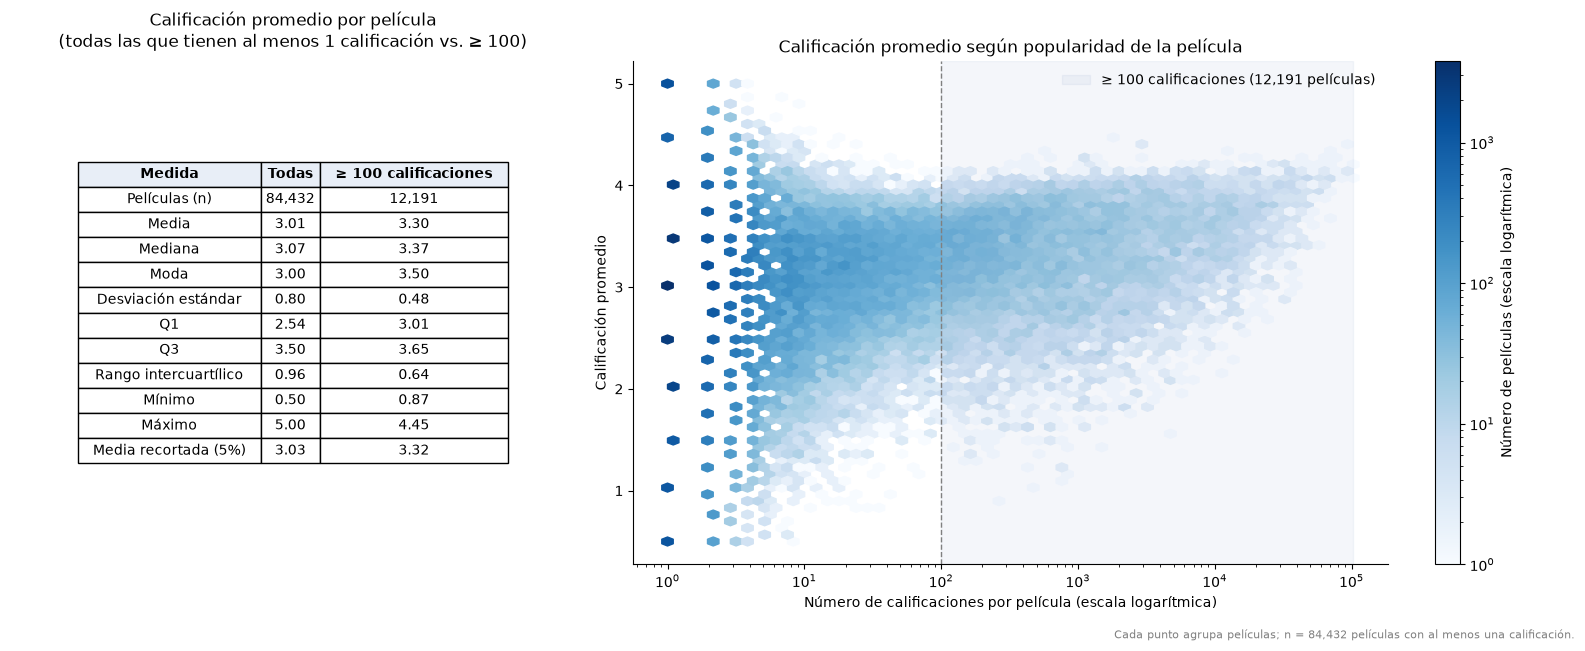

In [10]:
UMBRAL = 100 
t = movie_rating_stats.set_index("variable").T
t.columns.name = None
col_todas, col_100 = t.columns[:2]

etiquetas = {
    "n": "Películas (n)",
    "media": "Media",
    "mediana": "Mediana",
    "moda": "Moda",
    "desviacion_muestral": "Desviación estándar",
    "q1": "Q1",
    "q3": "Q3",
    "IQR": "Rango intercuartílico",
    "mínimo": "Mínimo",
    "máximo": "Máximo",
    "media_recortada_5pct": "Media recortada (5%)",
}

def fmt(medida, valor):
    valor = float(valor)
    return f"{valor:,.0f}" if medida == "n" else f"{valor:.2f}"

filas = [(etiquetas[m], fmt(m, t.loc[m, col_todas]), fmt(m, t.loc[m, col_100])) for m in etiquetas]

# ---------- Datos del gráfico ----------
pel = movies.dropna(subset=["rating_mean"])
print(len(pel))
n_umbral = int((pel["rating_count"] >= UMBRAL).sum())

# ---------- Figura ----------
fig, (ax_tabla, ax_graf) = plt.subplots(
    1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.2, 2]}
)

ax_tabla.axis("off")
tbl = ax_tabla.table(cellText=filas, colLabels=["Medida", "Todas", f"≥ {UMBRAL} calificaciones"],
                     cellLoc="center", loc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.5)
tbl.auto_set_column_width(col=[0, 1, 2])
for (i, j), celda in tbl.get_celld().items():
    if i == 0:
        celda.set_text_props(weight="bold")
        celda.set_facecolor("#E8EEF7")
ax_tabla.set_title("Calificación promedio por película\n(todas las que tienen al menos 1 calificación vs. ≥ 100)", pad=10)

hb = ax_graf.hexbin(pel["rating_count"], pel["rating_mean"], xscale="log",
                    gridsize=60, bins="log", cmap="Blues", mincnt=1)
ax_graf.axvline(UMBRAL, color="gray", linestyle="--", linewidth=1)
ax_graf.axvspan(UMBRAL, pel["rating_count"].max(), color="#4C72B0", alpha=0.06,
                label=f"≥ {UMBRAL} calificaciones ({n_umbral:,} películas)")
fig.colorbar(hb, ax=ax_graf, label="Número de películas (escala logarítmica)")

ax_graf.set_xlabel("Número de calificaciones por película (escala logarítmica)")
ax_graf.set_ylabel("Calificación promedio")
ax_graf.set_title("Calificación promedio según popularidad de la película")
ax_graf.legend(frameon=False, loc="upper right")
ax_graf.spines[["top", "right"]].set_visible(False)

fig.text(0.99, 0.01, f"Cada punto agrupa películas; n = {len(pel):,} películas con al menos una calificación.",
         ha="right", fontsize=8, color="gray")

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Interpretación.** El gráfico relaciona el número de calificaciones de cada película con su calificación promedio. Las películas con pocas calificaciones presentan promedios muy dispersos, mientras que a medida que aumenta el número de calificaciones los promedios se concentran en un rango más estrecho. Además, el límite inferior de los promedios sube con la popularidad: las películas muy calificadas rara vez tienen promedios bajos. 

Esto es relevante porque el promedio de una película con pocas calificaciones es poco confiable: unas cuantas calificaciones bastan para moverlo. Por eso, al comparar géneros y décadas **ponderamos por el número de calificaciones** y, en el análisis de dispersión por género, **excluimos las películas con menos de 100 calificaciones** 

**Limitaciones.** El gráfico es descriptivo y no permite concluir que las películas más populares sean mejores

## 5. Forma de distribución: asimetría y curtosis
La asimetría positiva indica cola hacia la derecha y la negativa, hacia la izquierda. Cuando la curtosisi reporta valores altos pueden reflejar colas pesadas o valores extremos, no necesariamente una forma normal.

In [29]:
# 7. FORMA ESTADÍSTICA
shape_rows = []
for c in count_vars + ["rating_mean"]:
    s = pd.to_numeric(movies[c], errors="coerce").dropna()
    if c == "rating_mean": s = s[movies.loc[s.index, "rating_count"] > 0]
    skew = s.skew() if len(s)>2 and s.nunique()>2 else np.nan
    kurt = s.kurt() if len(s)>3 and s.nunique()>3 else np.nan
    shape_rows.append({"variable":c,"n":len(s),"pct_ceros":100*(s==0).mean(),
                       "asimetria_fisher":skew,"orientacion": ("derecha" if skew>0 else "izquierda" if skew<0 else "simétrica aprox.") if pd.notna(skew) else "no evaluable",
                       "exceso_curtosis_fisher":kurt})
shape = pd.DataFrame(shape_rows)
display(shape)
# Momentos de la distribución de calificaciones individuales a partir de frecuencias.
mu = mean_event
m2 = np.average((v-mu)**2, weights=w)
m3 = np.average((v-mu)**3, weights=w)
m4 = np.average((v-mu)**4, weights=w)
print("Asimetría ponderada de calificaciones (momento poblacional):", m3/m2**1.5 if m2>0 else np.nan)
print("Exceso de curtosis ponderado de calificaciones (momento poblacional):", m4/m2**2-3 if m2>0 else np.nan)


,variable,n,pct_ceros,asimetria_fisher,orientacion,exceso_curtosis_fisher
0,rating_count,87585,3.5999,15.9020,derecha,360.2967
1,rating_users,87585,3.5999,15.9020,derecha,360.2967
2,tag_application_count,87585,41.4021,18.5215,derecha,592.1917
3,non_null_tag_count,87585,41.4021,18.5215,derecha,592.1949
4,distinct_tags,87585,41.4021,7.8836,derecha,82.2088
5,tag_users,87585,41.4021,24.6268,derecha,"1,469.3666"
6,rating_mean,84432,0.0000,-0.6101,izquierda,1.0645


Asimetría ponderada de calificaciones (momento poblacional): -0.7190238734384279
Exceso de curtosis ponderado de calificaciones (momento poblacional): 0.25944395897200456


### 6. ¿Qué valores atípicos hay y qué hacemos con ellos?

Para detectar valores atípicos aplicamos la regla de Tukey, **[Q1 − 1.5·RIQ, Q3 + 1.5·RIQ]**, al número de calificaciones. Como esta variables es un conteo, fijamos el límite inferior en cero. Además complementamos el analisis  con los percentiles 95, 99 y 99.9.

Nuestro criterio es **investigar antes de excluir**. Separamos tres situaciones:

- **Películas con muchísimas calificaciones** (hasta 102,929): la popularidad extrema puede ser genuina, por lo que no se eliminan automáticamente.
- **Películas con pocas calificaciones:** no se tratan como errores. Su promedio es poco confiable y lo manejamos con el umbral de **100 calificaciones** definido en el resto del análisis.
- **Calificaciones individuales de 0.5 y 5.0:** son los límites válidos de la escala, no errores por sí mismos.

Para distinguir un dato anómalo de un dato extremo pero legítimo, comprobamos además cinco reglas de consistencia que, de incumplirse, sí indicarían un error:

- No hay conteos negativos.
- Ningún promedio queda fuera de la escala de 0.5 a 5.0.
- Ninguna película tiene promedio sin calificaciones.
- Ninguna película tiene desviación estándar con menos de dos calificaciones.
- Ninguna película tiene más usuarios que calificaciones.

Por último, revisamos las películas con **100 o más calificaciones y mayor desviación estándar**

In [12]:
# 8. DETECCIÓN DE ATÍPICOS EN VARIABLES DE ACTIVIDAD
outlier_rows=[]
for c in count_vars:
    s=movies[c].dropna()
    q1,q3=s.quantile([.25,.75]); iqr=q3-q1; lo=max(0, q1-1.5*iqr); hi=q3+1.5*iqr
    outlier_rows.append({"variable":c,"q1":q1,"q3":q3,"IQR":iqr,
                         "limite_inferior":lo,"limite_superior":hi,"n_fuera":int(((s<lo)|(s>hi)).sum()),
                         "pct_fuera":100*((s<lo)|(s>hi)).mean(),
                         "p95":s.quantile(.95),"p99":s.quantile(.99),"p999":s.quantile(.999),
                         "maximo":s.max(),"IQR_cero":iqr==0})
outliers=pd.DataFrame(outlier_rows)
display(outliers)


,variable,q1,q3,IQR,limite_inferior,limite_superior,n_fuera,pct_fuera,p95,p99,p999,maximo,IQR_cero
0,rating_count,2.0000,23.0000,21.0000,0,54.5000,15437,17.6252,"1,006.6000","8,877.8000","37,690.3440",102929,False


 El **50% central** de las películas recibe entre **2 y 23 calificaciones** (Q1 y Q3), por lo que el rango intercuartílico es de solo 21. Con la regla de Tukey, el límite superior queda en **54.5**: cualquier película con **55 o más calificaciones** se marca como atípica. Esto afecta a **15,437 películas (17.6%)**.

In [13]:
print("Casos de máxima actividad para investigar; no se excluyen:")
display(movies.nlargest(12,"rating_count")[["movieId","title_clean","rating_count","rating_mean","tag_application_count"]])

Casos de máxima actividad para investigar; no se excluyen:


,movieId,title_clean,rating_count,rating_mean,tag_application_count
314,318,"Shawshank Redemption, The",102929,4.4046,4892
351,356,Forrest Gump,100296,4.0527,3581
292,296,Pulp Fiction,98409,4.1970,6697
2480,2571,"Matrix, The",93808,4.1564,5722
585,593,"Silence of the Lambs, The",90330,4.1484,3469
257,260,Star Wars: Episode IV - A New Hope,85010,4.0998,6519
2867,2959,Fight Club,77332,4.2288,5532
475,480,Jurassic Park,75233,3.6986,1510
522,527,Schindler's List,73849,4.2370,2059
4888,4993,"Lord of the Rings: The Fellowship of the Ring,...",73122,4.0921,2550


In [17]:
print("Casos con >=100 evaluaciones y dispersión interna más alta:")
display(movies.loc[movies["rating_count"]>=100].nlargest(10,"rating_std")[["movieId","title_clean","rating_count","rating_mean","rating_std"]])


Casos con >=100 evaluaciones y dispersión interna más alta:


,movieId,title_clean,rating_count,rating_mean,rating_std
1277,1311,Santa with Muscles,163,2.5521,1.7075
14392,74754,"Room, The",1179,2.4822,1.6428
21478,110603,God's Not Dead,241,2.4108,1.6277
12322,59295,Expelled: No Intelligence Allowed,166,2.0964,1.5963
11344,50703,"Secret, The",204,2.3186,1.5738
1382,1421,Grateful Dead,190,3.0421,1.5654
29196,133123,Barbie as The Princess & the Pauper,142,3.2817,1.5419
1347,1383,Adrenalin: Fear the Rush,149,2.2517,1.5264
52263,183589,Fifty Shades Freed,394,2.4987,1.5206
13101,66659,Tyler Perry's Madea Goes to Jail,142,2.5634,1.5134


In [16]:
checks = {
    "conteos_negativos": int((movies[count_vars]<0).sum().sum()),
    "rating_mean_fuera_escala": int(((movies["rating_mean"].notna()) & ~movies["rating_mean"].between(0.5,5)).sum()),
    "media_sin_votos": int(((movies["rating_count"]==0)&movies["rating_mean"].notna()).sum()),
    "std_sin_al_menos_dos_votos": int(((movies["rating_count"]<2)&movies["rating_std"].notna()).sum()),
    "usuarios_mayores_que_calificaciones": int((movies["rating_users"]>movies["rating_count"]).sum()),
}
display(pd.Series(checks, name="incidencias"))

conteos_negativos                      0
rating_mean_fuera_escala               0
media_sin_votos                        0
std_sin_al_menos_dos_votos             0
usuarios_mayores_que_calificaciones    0
Name: incidencias, dtype: int64

**Interpretación.** La regla de Tukey marca como atípicas a **15,437 películas (17.6%)**. Un porcentaje tan alto no señala errores: refleja que la distribución tiene una cola muy larga, donde la mayoría de las películas recibe pocas calificaciones y unas cuantas concentran gran parte de la actividad. Por eso no excluimos ninguna película por este criterio. Las cinco reglas de consistencia dan **cero incidencias**, así que no encontramos datos erróneos en estas variables. Entre las películas con 100 o más calificaciones, las de mayor dispersión (como *Santa with Muscles*, *The Room* o *God's Not Dead*) tienen promedios bajos o medios, entre 2.1 y 3.3, y desviaciones de 1.5 a 1.7. Es decir, reciben calificaciones muy altas y muy bajas a la vez. Una explicación posible es que dividen la opinión del público, pero los datos no permiten comprobarlo.

## 7. Calidad de datos y patrones de faltantes
Se evalúa número y porcentaje de nulos por variable. La tabla `column_quality` proviene de las fuentes **anteriores** a la consolidación y se muestra aparte: no se debe comparar directamente su denominador con el consolidado.


In [31]:
# 9. FALTANTES POR COLUMNA Y PATRONES CONJUNTOS
missing = pd.DataFrame({"variable":movies.columns,"faltantes":movies.isna().sum().values,
                        "pct_faltantes":movies.isna().mean().values*100,
                        "dtype":movies.dtypes.astype(str).values}).sort_values("faltantes",ascending=False)
display(missing)
print("Diagnóstico de faltantes estructurales en medidas de rating:")
display(pd.crosstab(movies["rating_count"].clip(upper=2).map({0:"0 evaluaciones",1:"1 evaluación",2:"2+ evaluaciones"}),
                    movies["rating_std"].isna(), rownames=["actividad"],colnames=["rating_std ausente"], margins=True))
print("Patrones combinados de ausencia: IDs externos y medias de rating")
cols = ["imdbId","tmdbId","rating_mean","rating_std"]
patterns = movies[cols].isna().rename(columns=lambda c:c+"_nulo")
display(patterns.value_counts(dropna=False).rename("peliculas").reset_index().head(20))
print("Comparación cobertura de TMDb según actividad:")
display(pd.crosstab(movies["has_ratings"], movies["tmdbId"].isna(), normalize="index"))
print("Informe de calidad preintegración:")
display(tables["column_quality"])
print("Resultados de validación y referencial:")
display(tables["post_validation"])
display(tables["referential_integrity"])

,variable,faltantes,pct_faltantes,dtype
8,rating_std,21760,24.8444,float64
10,rating_max,3153,3.5999,float64
7,rating_mean,3153,3.5999,float64
9,rating_min,3153,3.5999,float64
2,year,617,0.7045,float64
5,tmdbId,124,0.1416,float64
1,title_clean,1,0.0011,str
0,movieId,0,0.0000,int64
3,genres,0,0.0000,str
4,imdbId,0,0.0000,int64


Diagnóstico de faltantes estructurales en medidas de rating:


rating_std ausente,False,True,All
actividad,,,
0 evaluaciones,0,3153,3153
1 evaluación,0,18607,18607
2+ evaluaciones,65825,0,65825
All,65825,21760,87585


Patrones combinados de ausencia: IDs externos y medias de rating


,imdbId_nulo,tmdbId_nulo,rating_mean_nulo,rating_std_nulo,peliculas
0,False,False,False,False,65735
1,False,False,False,True,18575
2,False,False,True,True,3151
3,False,True,False,False,90
4,False,True,False,True,32
5,False,True,True,True,2


Comparación cobertura de TMDb según actividad:


... (2 outputs left out)

,dataset,column,dtype,non_null,nulls,null_pct,unique_non_null
0,movies,movieId,int32,87585,0,0.0000,87585
1,movies,title,string,87585,0,0.0000,87382
2,movies,genres,string,87585,0,0.0000,1798
3,ratings,userId,int32,32000204,0,0.0000,200948
4,ratings,movieId,int32,32000204,0,0.0000,84432
5,ratings,rating,float32,32000204,0,0.0000,10
6,ratings,timestamp,int64,32000204,0,0.0000,25976523
7,tags,userId,int32,2000072,0,0.0000,15848
8,tags,movieId,int32,2000072,0,0.0000,51323
9,tags,tag,string,2000055,17,0.0008,140979


Resultados de validación y referencial:


,test,passed
0,movieId único en movies_consolidated,True
1,Se preservó el total de películas,True
2,Combinación movieId-genre única,True
3,Géneros vinculados a películas existentes,True
4,Agregado de ratings reconcilia con ratings ori...,True
5,Agregado de tags reconcilia con tags original,True


,child_table,distinct_movie_ids,ids_found_in_movies,orphan_movie_ids
0,ratings,84432,84432,0
1,tags,51323,51323,0
2,links,87585,87585,0


### 8. ¿Se relaciona la calificación promedio con la popularidad y la dispersión?

Para ver si la calificación de una película se asocia con su popularidad, medimos la relación entre tres variables calculadas **por película**:

- **Número de calificaciones** (`rating_count`): qué tan popular o conocida es la película.
- **Calificación promedio** (`rating_mean`): qué tan bien la valoran, en promedio.
- **Desviación estándar de las calificaciones** (`rating_std`): qué tanto se parecen o difieren las calificaciones que recibe.

Usamos dos coeficientes de correlación:

- **Pearson**, que mide la relación **lineal** y es sensible a los valores extremos.
- **Spearman**, que mide si la relación es **monótona** (si una variable tiende a subir cuando la otra sube) y no depende de la forma de la distribución.

Repetimos el cálculo en dos muestras:

- **Todas las películas con al menos una calificación** (84,432; para la desviación estándar, las **65,825** con al menos dos calificaciones, porque con una sola no existe).
- **Películas con 100 o más calificaciones** (12,191), para ver **cómo cambian las asociaciones cuando el promedio de cada película se apoya en más datos**.


In [19]:
variables = ["rating_count", "rating_mean", "rating_std"]
full = movies.loc[movies["rating_count"] > 0, variables].copy()
restricted = movies.loc[movies["rating_count"] >= 100, variables].copy()

pairs = [("rating_count", "rating_mean"),
         ("rating_count", "rating_std"),
         ("rating_mean", "rating_std")]

filas = []
for nombre, sub in [("≥ 1 calificación", full), ("≥ 100 calificaciones", restricted)]:
    for a, b in pairs:
        z = sub[[a, b]].dropna()
        filas.append({"muestra": nombre, "variable_x": a, "variable_y": b,
                      "n_pares": len(z),
                      "pearson": round(z[a].corr(z[b], method="pearson"), 3),
                      "spearman": round(z[a].corr(z[b], method="spearman"), 3)})

resumen_correlaciones = pd.DataFrame(filas)


In [23]:
resumen_correlaciones

,muestra,variable_x,variable_y,n_pares,pearson,spearman
0,≥ 1 calificación,rating_count,rating_mean,84432,0.0980,0.1550
1,≥ 1 calificación,rating_count,rating_std,65825,-0.0040,0.1800
2,≥ 1 calificación,rating_mean,rating_std,65825,-0.1680,-0.2400
3,≥ 100 calificaciones,rating_count,rating_mean,12191,0.2130,0.1910
4,≥ 100 calificaciones,rating_count,rating_std,12191,-0.0870,-0.1040
5,≥ 100 calificaciones,rating_mean,rating_std,12191,-0.5040,-0.5140


**Interpretación.** Para leer los coeficientes usamos una referencia habitual: valores cercanos a 0 indican una relación muy débil, alrededor de ±0.3 una relación débil a moderada, y de ±0.5 en adelante una relación moderada. Interpretamos **Spearman como medida principal**, porque el número de calificaciones tiene una cola muy larga, y usamos Pearson como contraste.

- **Popularidad y calificación promedio:** la relación es positiva pero débil. Con todas las películas, Pearson es **0.098** y Spearman **0.155**. Con 100 o más calificaciones sube a **0.213** y **0.191**. Las películas con más calificaciones tienden a tener un promedio algo mayor, pero el número de calificaciones explica muy poco del promedio

- **Popularidad y dispersión:** no hay una relación clara. Con todas las películas, Pearson es casi nulo (**−0.004**) pero Spearman es ligeramente positivo (**0.180**), y con 100 o más calificaciones ambos son levemente negativos (**−0.087** y **−0.104**). Los signos cambian según la medida y la muestra, así que no hay evidencia de que tener más calificaciones haga que las calificaciones se parezcan más o menos entre sí.

- **Calificación promedio y dispersión:** es la relación más fuerte y la única que cambia de forma notable al aplicar el umbral. Con todas las películas es débil (Pearson = **−0.168**; Spearman = **−0.240**), pero con 100 o más calificaciones se vuelve **moderada** (**−0.504** y **−0.514**), lo que equivale a cerca del 25% de variabilidad lineal compartida (0.504²). Las películas mejor calificadas tienden a recibir calificaciones más parecidas entre sí, y las peor calificadas, más dispersas.

El patrón principal es que las asociaciones se hacen más claras cuando cada promedio se apoya en más calificaciones 

**Limitaciones.** Son asociaciones descriptivas, no causales.

### 9. ¿Cómo cambia la calificación promedio y el número de calificaciones por género?
Para analizar cómo se comportan las evaluaciones según el género, seguimos las siguientes reglas:
* **Cobertura mediante tasas:** comparamos la proporción de evaluaciones entre géneros.
* **Cálculo de puntuaciones:** cada película se cuenta una sola vez **dentro de cada género**, restringiendo el análisis a títulos con **$\ge 100$ votos**.
* **Categorías no excluyentes:** como los géneros pueden superponerse en una misma película, las filas no representan grupos independientes.
* **Distribución y resumen:** incluimos un *boxplot* para visualizar la distribución de las calificaciones por género.

In [12]:
# 11. ASOCIACIONES CATEGÓRICAS Y COMPARACIÓN MULTILABEL
per_genre = movie_genres.merge(
    movies[["movieId","rating_count","rating_mean","has_ratings","tag_application_count"]],
    on="movieId",how="left",validate="many_to_many")
genre_summary = per_genre.groupby("genre").agg(
    peliculas=("movieId","nunique"),
    pct_con_evaluaciones=("has_ratings",lambda x:100*x.mean()),
    mediana_evaluaciones=("rating_count","median"),
    media_evaluaciones=("rating_count","mean"))
eligible = per_genre.loc[per_genre["rating_count"]>=100]
rating_genre = eligible.groupby("genre").agg(
    peliculas_con_100_votos=("movieId","nunique"),
    media_puntuacion_por_pelicula=("rating_mean","mean"),
    mediana_puntuacion_por_pelicula=("rating_mean","median"))
genre_summary=genre_summary.join(rating_genre)
display(genre_summary.sort_values("peliculas",ascending=False))


,peliculas,pct_con_evaluaciones,mediana_evaluaciones,media_evaluaciones,peliculas_con_100_votos,media_puntuacion_por_pelicula,mediana_puntuacion_por_pelicula
genre,,,,,,,
Drama,34175,97.0066,6.0000,408.8741,5772,3.4516,3.5110
Comedy,23124,97.0766,6.0000,484.6448,4231,3.1927,3.2460
Thriller,11823,97.7332,7.0000,734.1169,2498,3.2274,3.2517
Romance,10369,96.9042,6.0000,532.8011,1919,3.3585,3.4161
Action,9668,96.1523,8.0000,999.7117,2111,3.1522,3.1899
Documentary,9363,97.2231,3.0000,45.6427,547,3.6476,3.7202
Horror,8654,97.8507,6.0000,287.9957,1357,2.9776,3.0322
(no genres listed),7080,92.5847,2.0000,7.8387,47,3.4514,3.5340
Crime,6976,96.1009,7.0000,770.2195,1469,3.3541,3.4105


**Interpretación de los resultados por género**

Al analizar el volumen de películas, la cobertura de evaluaciones y las puntuaciones por género (restringiendo la calificación a títulos con $\ge 100$ votos), destacan los siguientes hallazgos:

* **Concentración del catálogo frente a volumen de votos:** **Drama** ($34,175$ películas) y **Comedy** ($23,124$) dominan ampliamente el catálogo en cantidad de títulos, pero no son los que acumulan más votos por película. Géneros como **Adventure** (media de $1,405.1$ evaluaciones), **Sci-Fi** ($1,165.1$) y **Musical** ($1,094.9$) concentran mucha mayor atención por título, mientras que **IMAX** destaca como un caso extremo con $100\%$ de cobertura y una mediana de $3,197$ votos por película.
* **Fuerte sesgo en la distribución de evaluaciones:** en prácticamente todos los géneros existe una brecha enorme entre la mediana y la media de evaluaciones (por ejemplo, en **Drama** la mediana es de apenas $6$ votos frente a una media de $408.9$, y en **Adventure** es de $10$ frente a $1,405.1$). Esto confirma que unos pocos títulos muy populares arrastran el promedio hacia arriba, mientras la mayoría recibe pocas calificaciones.

**Limitaciones y consideraciones metodológicas**
* **Superposición de categorías (*multilabel*) y porcentajes no aditivos:** dado que una misma película puede pertenecer simultáneamente a varios géneros (pertenencias múltiples), las filas no representan grupos independientes y los porcentajes sobre el catálogo por género **no suman $100\%$**.
* **Sesgo de selección por el umbral de $\ge 100$ votos:** al calcular la media y mediana de puntuación únicamente sobre películas con al menos $100$ votos, se excluye a la gran mayoría del catálogo en varios géneros (por ejemplo, en **Documentary** solo $547$ de $9,363$ títulos cumplen el filtro

127014


C:\Users\igpea\AppData\Local\Temp\ipykernel_36396\1391944058.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(datos, vert=False, tick_labels=orden, showfliers=False)


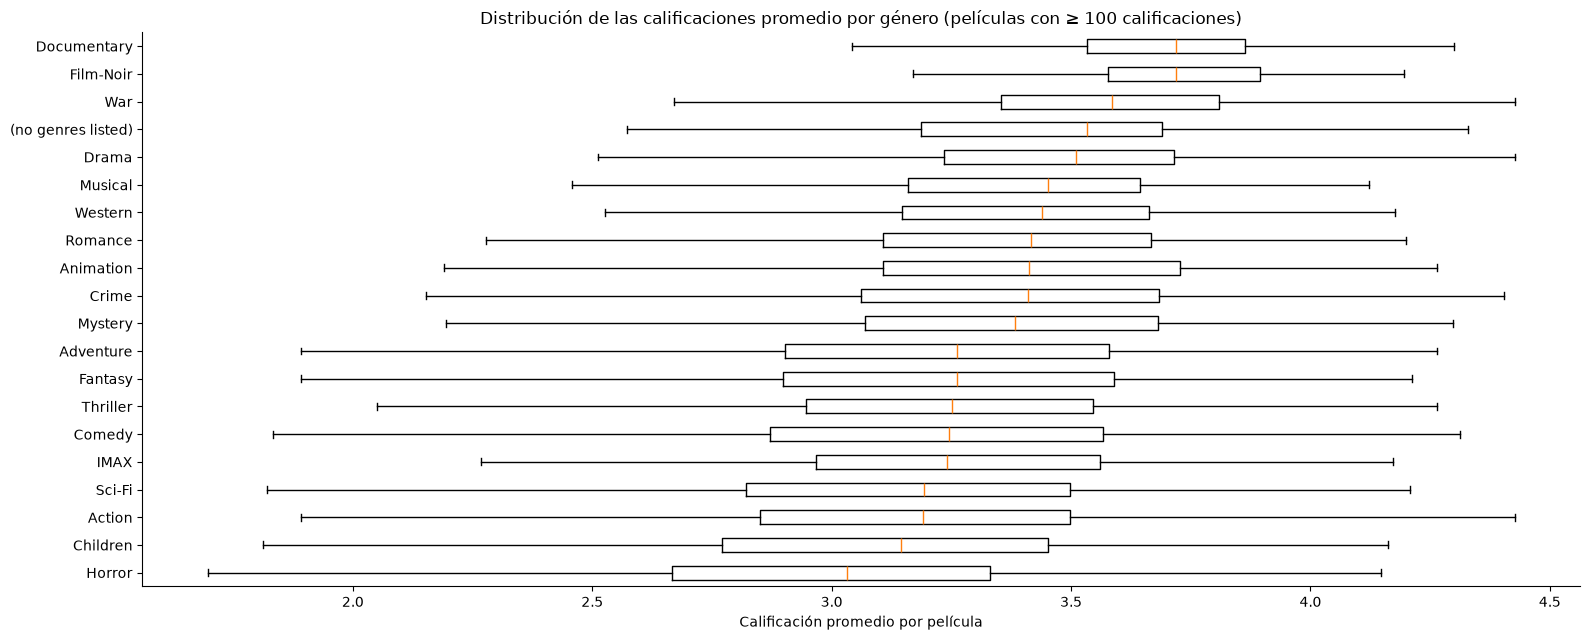

In [14]:
MIN_CALIF = 100
b = per_genre[per_genre["rating_count"] >= 100]
b_out = per_genre[per_genre["rating_count"] < 100]["movieId"].count()
print(b_out)
orden = b.groupby("genre")["rating_mean"].median().sort_values().index #ordena los género de menor a mayor mediana
datos = [b.loc[b["genre"] == g, "rating_mean"] for g in orden]

fig, ax = plt.subplots(figsize=(16, 6.5))
ax.boxplot(datos, vert=False, tick_labels=orden, showfliers=False)
ax.set_xlabel("Calificación promedio por película")
ax.set_title(f"Distribución de las calificaciones promedio por género (películas con ≥ {MIN_CALIF} calificaciones)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Interpretación.** El gráfico muestra, para cada género, cómo se distribuyen los promedios de calificación de sus películas. Film-Noir y Documentary tienen las medianas más altas (alrededor de 3.65), y Horror la más baja (cerca de 3.0). Film-Noir, además, presenta una de las cajas más angostas, por lo que sus películas son relativamente parecidas entre sí, mientras que Horror es uno de los géneros más dispersos, con películas desde promedios cercanos a 1.7 hasta más de 4.

Un hallazgo importante es que las cajas de los géneros con mejores calificaciones (Documentary y Film-Noir) no se traslapan con las demás. Por tanto,para estos dos géneros la pelicula típica si tiene un promedio distinto 

**Limitaciones.** Se grafican promedios por película, no calificaciones individuales, y cada película pesa igual sin importar su número de calificaciones. Se excluyeron las películas con menos de 100 calificaciones ([127014] películas), y no se muestran los valores atípicos. 

### 9. ¿Cómo varían las calificaciones de las películas según su año de estreno?
Con el fin de evaluar si las películas clásicas reciben mejores calificaciones que las más recientes, extrajimos el año de estreno a partir del título, cuantificamos los registros faltantes y definimos qué hacer con ellos a partir de ese resultado.


In [17]:
#Número de películas sin año
sin_anio = movies["year"].isna()

n_total = len(movies)
n_sin_anio = int(sin_anio.sum())
print(f"{n_sin_anio:,} de {n_total:,} películas sin año ({sin_anio.mean():.2%})")

617 de 87,585 películas sin año (0.70%)


**617** películas no tienen un año registrado de estreno, lo cual representa el **0.70%** del total. Esto ocurre por una cuestión de formato: en esos casos el título no contiene el año entre paréntesis, de donde se extrajo la variable `year`. Como representan una fracción mínima del conjunto de datos, la decisión es eliminarlos antes de continuar con el análisis.

In [18]:
movies_consolidated_clean = movies.dropna(subset=["year", "rating_mean"]).copy()
movies_consolidated_clean["decada"] = (movies_consolidated_clean["year"] // 10) * 10
movies_consolidated_clean["suma"] = movies_consolidated_clean["rating_mean"] * movies_consolidated_clean["rating_count"]
por_decada = movies_consolidated_clean.groupby("decada").agg(
    n_peliculas=("movieId", "nunique"),
    n_calif=("rating_count", "sum"),
    media_peliculas=("rating_mean", "mean"),   # cada película pesa igual
    suma=("suma", "sum"),
)
por_decada["media_ponderada"] = por_decada["suma"] / por_decada["n_calif"]   # cada calificación pesa igual
por_decada = por_decada.drop(columns="suma").sort_index()

Décadas excluidas: [1870.0, 1880.0, 1890.0, 1900.0, 1910.0]


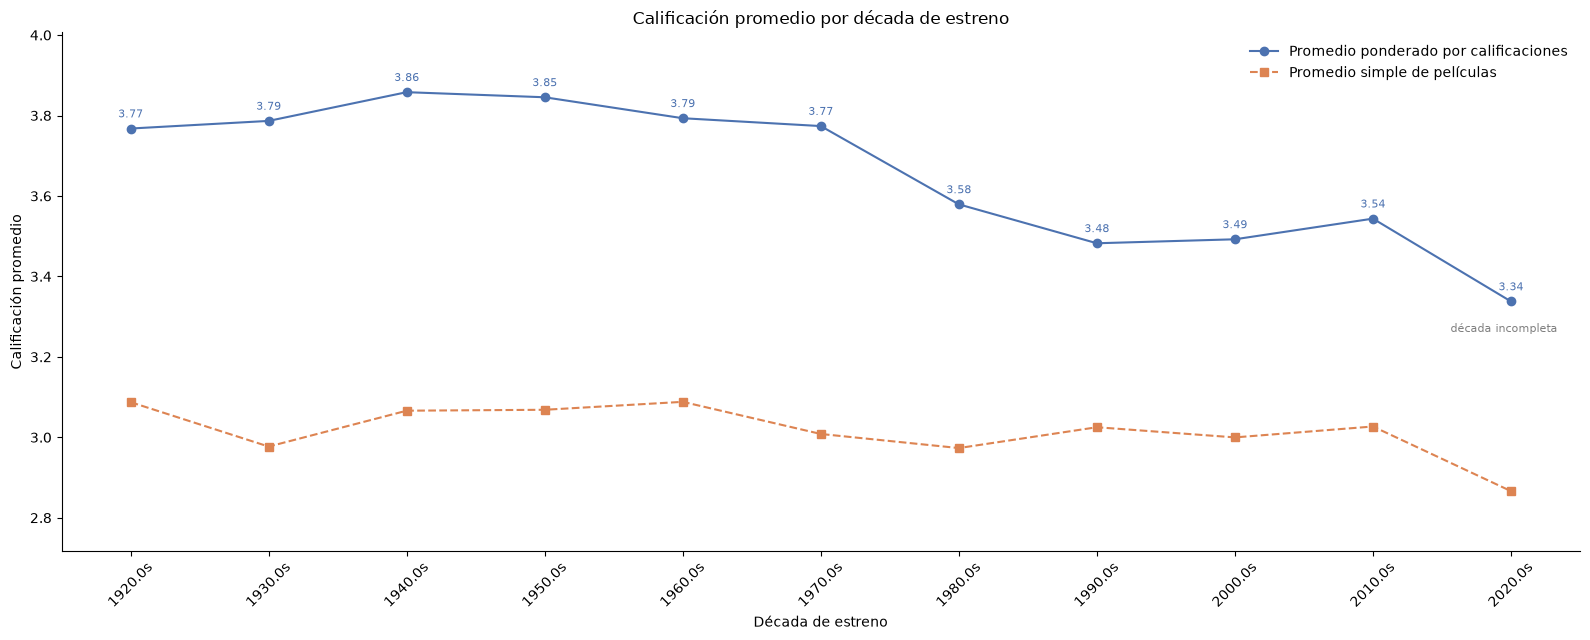

In [22]:
UMBRAL = 500 # Se excluyeron decadas con muy pocas películas, ya que en esos casos el promesio es inestable

d = por_decada.sort_index() #asigna un orden
d = d[d["n_peliculas"] >= 500]
print("Décadas excluidas:", por_decada.index.difference(d.index).tolist())

fig, ax = plt.subplots(figsize=(16, 6.5))

ax.plot(d.index, d["media_ponderada"], marker="o", color="#4C72B0",
        label="Promedio ponderado por calificaciones")
ax.plot(d.index, d["media_peliculas"], marker="s", linestyle="--", color="#DD8452",
        label="Promedio simple de películas")

# Valor sobre cada punto de la línea ponderada
for x, y in zip(d.index, d["media_ponderada"]):
    ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", color="#4C72B0", xytext=(0, 8),
               ha="center", fontsize=8,)

 # La última década está incompleta
if 2020 in d.index:
   ax.annotate("década incompleta", (2020, d.loc[2020, "media_ponderada"]),
                 textcoords="offset points", xytext=(-5, -22), ha="center",
                 fontsize=8, color="gray")

ax.set_xticks(d.index)
ax.set_xticklabels([f"{x}s" for x in d.index], rotation=45)
ax.margins(y=0.15)
ax.set_xlabel("Década de estreno")
ax.set_ylabel("Calificación promedio")
ax.set_title("Calificación promedio por década de estreno")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretación.** Al promediar las calificaciones ponderadas por el número de calificaciones, las películas estrenadas entre las décadas de 1920 y 1970 tienen promedios más altos (entre 3.77 y 3.86) que las estrenadas desde 1980 (entre 3.48 y 3.58), con un descenso adicional en la década de 2020 (3.34). Es decir, **las películas antiguas reciben mejores calificaciones que las recientes**, y la diferencia se concentra en un cambio entre los años setenta y ochenta, más que en una caída gradual.

Sin embargo, este resultado depende de cómo se promedie: el **promedio simple de las películas** apenas varía entre décadas (alrededor de 3.0), porque está dominado por títulos con pocas calificaciones. La diferencia aparece, por tanto, en las películas más vistas y calificadas, no en el catálogo en general.

**Limitaciones.** 
Las décadas anteriores a 1920 se excluyeron por tener muy pocos datos, y la década de 2020 está incompleta y sus películas han tenido menos tiempo para acumular calificaciones. **Los resultados son descriptivos: no permiten afirmar que la antigüedad de una película cause mejores calificaciones.**

## 9. Conclusiones
Se redacta un resumen a partir de lo calculado.

In [34]:
# 12. SÍNTESIS AUTOMÁTICA DE RESULTADOS
n_movies=len(movies)
n_rated=int(movies["has_ratings"].sum())
n_tagged=int(movies["has_tags"].sum())
median_v=float(movies["rating_count"].median())
mean_v=float(movies["rating_count"].mean())
mode_rating=float(rd.loc[rd["frequency"].idxmax(),"rating"])
rank_corr=correlation_summary.query('muestra == "n>=100" and variable_x == "rating_count" and variable_y == "rating_mean"')["spearman"].iloc[0]
most_genre=genre_summary["peliculas"].idxmax()
print("¿QUÉ REPRESENTAN LOS REGISTROS MÁS IMPORTANTES?")
print(f"• Catálogo: {n_movies:,} películas, {n_rated:,} con evaluaciones y {n_tagged:,} con etiquetas.")
print(f"• Distribución: {N:,} eventos de rating; puntuación modal {mode_rating:g} y media por evento {mean_event:.3f}.")
print("• Las películas con más eventos documentan concentración de actividad; sin eventos, no se puede estimar opinión.")
print("\n¿QUÉ VARIABLES SE TIENEN?")
print(f"• {len(movies.columns)} columnas de catálogo: identificadores y etiquetas nominales, flags dicotómicos, conteos de razón y resúmenes de rating.")
print("• Géneros: variable nominal multilabel; rating original: ordinal discreta (intervalo aproximado para promedios).")
print("\n¿QUÉ PATRONES SE DETECTARON?")
print(f"• Votos por película: media {mean_v:.2f} y mediana {median_v:.2f}; la diferencia indica concentración de actividad." )
print(f"• Género con mayor presencia: {most_genre} ({int(genre_summary.loc[most_genre,'peliculas']):,} películas).")
print(f"• Asociación monotónica votos–media con >=100 votos (Spearman): {rank_corr:.3f}.")
print(f"• Se localizaron nulos en {int((missing['faltantes']>0).sum())} columnas, con diagnóstico de ausencia estructural y cobertura.")
print("• Los outliers se conservan, sujetos a revisión de reglas de negocio; no hay recodificación automática.")
print("\nLIMITACIONES")
print("• Sin datos originales de usuario y fecha: no se evalúan efectos temporales, cohortes o dependencia intrausuario.")
print("• Un género no es exclusivo y una correlación no demuestra causalidad.")

¿QUÉ REPRESENTAN LOS REGISTROS MÁS IMPORTANTES?
• Catálogo: 87,585 películas, 84,432 con evaluaciones y 51,323 con etiquetas.
• Distribución: 32,000,204 eventos de rating; puntuación modal 4 y media por evento 3.540.
• Las películas con más eventos documentan concentración de actividad; sin eventos, no se puede estimar opinión.

¿QUÉ VARIABLES SE TIENEN?
• 20 columnas de catálogo: identificadores y etiquetas nominales, flags dicotómicos, conteos de razón y resúmenes de rating.
• Géneros: variable nominal multilabel; rating original: ordinal discreta (intervalo aproximado para promedios).

¿QUÉ PATRONES SE DETECTARON?
• Votos por película: media 365.36 y mediana 5.00; la diferencia indica concentración de actividad.
• Género con mayor presencia: Drama (41,255 películas).
• Asociación monotónica votos–media con >=100 votos (Spearman): 0.191.
• Se localizaron nulos en 7 columnas, con diagnóstico de ausencia estructural y cobertura.
• Los outliers se conservan, sujetos a revisión de reglas

## Pruebas estadísticas e inferencia

Esta sección convierte los patrones del EDA en una lectura inferencial. La historia es la siguiente: las calificaciones varían por género y por popularidad, pero no todas las diferencias tienen la misma magnitud. Por ello, las pruebas no se presentan como comprobaciones aisladas: primero establecen si existe una diferencia global, después muestran cuáles grupos la producen y finalmente estiman si la asociación es relevante en la práctica.

### Convención metodológica
- La unidad principal es **una película** (`rating_mean`), no un evento individual de calificación.
- El umbral de significancia es **alpha = 0.05**.
- Los p-valores se interpretan junto con tamaños de efecto, medias, medianas y intervalos de confianza.
- A nivel de 32 millones de calificaciones, muestras grandes pueden generar p-valores cercanos a cero aunque el efecto práctico sea moderado.
- Género es una variable multietiqueta: una película puede pertenecer a varios grupos y, por tanto, las observaciones por género no son totalmente independientes.

Las pruebas desarrolladas son:

1. **ANOVA clásica, Levene y Kruskal-Wallis** para diferencias globales entre géneros.
2. **Tukey HSD** para localizar pares de géneros diferentes.
3. **Mann-Whitney U y Welch t** para comparar películas populares y no populares.
4. **Spearman** para evaluar asociación monotónica entre volumen y calificación.
5. **Chi-cuadrado con corrección de Bonferroni** para estudiar la relación entre género y popularidad.



In [35]:
# Dependencias estadísticas y configuración
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

try:
    from scipy.stats import tukey_hsd
except ImportError:
    tukey_hsd = None

plt.rcParams["figure.figsize"] = (10, 5)
alpha = 0.05

# Tabla base para análisis por película y género
per_movie = movies[["movieId", "rating_count", "rating_mean"]].merge(
    movie_genres,
    on="movieId",
    how="inner",
    validate="many_to_many",
)
per_movie = per_movie.dropna(subset=["rating_mean", "rating_count"])
print(f"Películas-género analizadas: {len(per_movie):,}")
print(f"Películas únicas con rating: {per_movie['movieId'].nunique():,}")
print(f"Géneros: {per_movie['genre'].nunique()}")
# Películas-género analizadas: 154,170
# Películas únicas con rating: 87,585
# Géneros: 19


Películas-género analizadas: 149,285
Películas únicas con rating: 84,432
Géneros: 19


### 1. ANOVA y comparaciones post hoc por género

**Pregunta.** ¿Las calificaciones medias difieren entre géneros cinematográficos?

**Hipótesis.** H0 establece que los géneros tienen la misma media poblacional de `rating_mean`; H1 establece que al menos un género difiere. La unidad observada es la calificación media de una película dentro de su género.

#### Lectura de las pruebas

- **ANOVA clásica (F):** compara la variación entre medias de género con la variación dentro de los grupos. Es la primera prueba global y responde si existe al menos una diferencia.
- **Levene con centro mediano:** verifica homogeneidad de varianzas. Esta elección es más robusta ante distribuciones asimétricas que el contraste clásico basado en medias.
- **Kruskal-Wallis:** proporciona una alternativa no paramétrica que compara rangos y no depende de medias ni de homogeneidad de varianzas.
- **Eta cuadrado (`eta_squared`):** mide qué proporción de la variación observada se asocia a las diferencias entre géneros.
- **Tukey HSD:** si existe diferencia global, compara todos los pares de géneros y controla el error por familia mediante intervalos y p-valores corregidos.

#### Resultado global

| Prueba | Estadístico | Resultado |
|---|---:|---|
| ANOVA clásica | F = 422.2444 | Rechaza H0 |
| Levene | W = 39.3388 | Rechaza homogeneidad de varianzas |
| Kruskal-Wallis | H = 8,611.4585 | Rechaza igualdad de distribuciones |

Los tres resultados globales tienen p-valores menores que 0.0001. El análisis, por tanto, encuentra diferencias estadísticamente claras entre géneros. Sin embargo, el **eta cuadrado es 0.0485**: aproximadamente el 4.85% de la variación se relaciona con el género. El efecto global es pequeño-moderado y no significa que el género determine por sí solo la calificación.

#### Resumen narrativo de los géneros

El mayor promedio de `rating_mean` corresponde a **Documentary** (3.3397), seguido de **Film-Noir** (3.3227) e **IMAX** (3.2367). En el extremo opuesto aparecen **Horror** (2.5477), **Sci-Fi** (2.7046) y **Action** (2.8393). Estas medias no representan una lista de géneros “mejores”: son promedios por película dentro de grupos multietiqueta.


Resumen por género:


,count,mean,median,std
genre,,,,
Documentary,9103,3.3397,3.5000,0.7461
Film-Noir,350,3.3227,3.3438,0.4599
IMAX,195,3.2367,3.2362,0.4248
Musical,1033,3.1932,3.2580,0.5032
War,2225,3.1736,3.2778,0.6899
Drama,39707,3.0944,3.1875,0.7652
Romance,10048,3.0904,3.1614,0.7817
Animation,4586,3.0581,3.1429,0.7295
Crime,6704,3.0227,3.0949,0.6969



Pruebas globales:


,prueba,estadístico,gl/grupos,p_valor,decisión
0,ANOVA clásica,422.2444,k=19,0.0000,Rechazar H0
1,Levene (homogeneidad),39.3388,k=19,0.0000,Varianzas distintas
2,Kruskal-Wallis,"8,611.4585",k=19,0.0000,Rechazar H0


Eta cuadrado (ANOVA): 0.0485


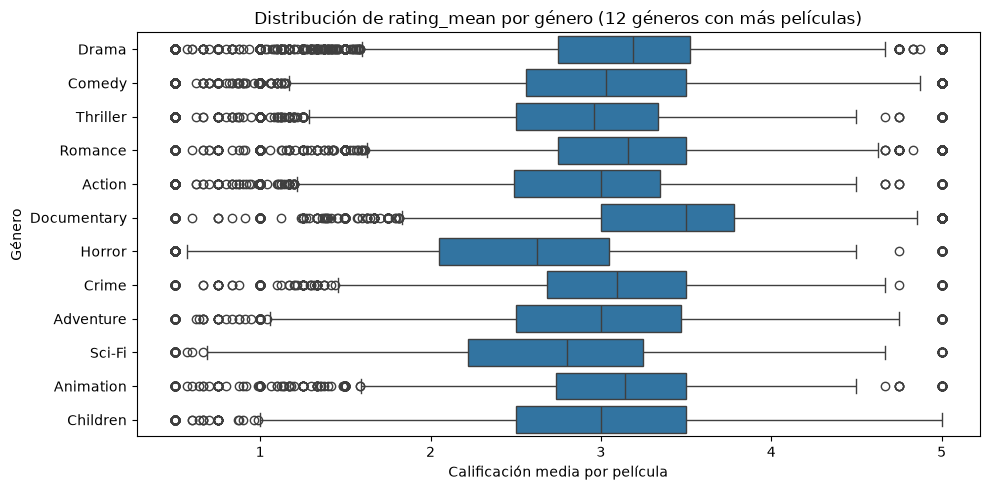

In [36]:
# ANOVA por género usando rating_mean por película
genre_counts = per_movie.groupby("genre")["rating_mean"].agg(["count", "mean", "median", "std"])
genre_counts = genre_counts.sort_values("mean", ascending=False)

eligible_genres = genre_counts.index[genre_counts["count"] >= 30].tolist()
groups = [per_movie.loc[per_movie["genre"] == g, "rating_mean"] for g in eligible_genres]

anova_f, anova_p = stats.f_oneway(*groups)
levene_stat, levene_p = stats.levene(*groups, center="median")
kruskal_h, kruskal_p = stats.kruskal(*groups)

# Eta cuadrado aproximado: variación entre géneros / variación total
all_values = pd.concat(groups)
overall_mean = all_values.mean()
ss_between = sum(len(g) * (g.mean() - overall_mean) ** 2 for g in groups)
ss_total = sum((all_values - overall_mean) ** 2)
eta_squared = ss_between / ss_total

anova_genre_results = pd.DataFrame([
    {"prueba": "ANOVA clásica", "estadístico": anova_f, "gl/grupos": f"k={len(groups)}", "p_valor": anova_p, "decisión": "Rechazar H0" if anova_p < alpha else "No rechazar H0"},
    {"prueba": "Levene (homogeneidad)", "estadístico": levene_stat, "gl/grupos": f"k={len(groups)}", "p_valor": levene_p, "decisión": "Varianzas distintas" if levene_p < alpha else "No hay evidencia de diferencias"},
    {"prueba": "Kruskal-Wallis", "estadístico": kruskal_h, "gl/grupos": f"k={len(groups)}", "p_valor": kruskal_p, "decisión": "Rechazar H0" if kruskal_p < alpha else "No rechazar H0"},
])
print("Resumen por género:")
display(genre_counts.loc[eligible_genres].head(20).round(4))
print("\nPruebas globales:")
display(anova_genre_results.round(6))
print(f"Eta cuadrado (ANOVA): {eta_squared:.4f}")

# Visualización homogénea: distribución por género (top 12 por tamaño)
top_genres = genre_counts.nlargest(12, "count").index.tolist()
plot_df = per_movie[per_movie["genre"].isin(top_genres)]
sns.boxplot(data=plot_df, x="rating_mean", y="genre", order=top_genres, orient="h")
plt.title("Distribución de rating_mean por género (12 géneros con más películas)")
plt.xlabel("Calificación media por película")
plt.ylabel("Género")
plt.tight_layout()
plt.show()


In [37]:
# Tukey HSD post hoc
if tukey_hsd is not None and anova_p < alpha:
    tukey = tukey_hsd(*groups)
    tukey_ci = tukey.confidence_interval(confidence_level=0.95)
    tukey_rows = []
    for i in range(len(eligible_genres)):
        for j in range(i + 1, len(eligible_genres)):
            tukey_rows.append({
                "género_1": eligible_genres[i],
                "género_2": eligible_genres[j],
                "diferencia_media": tukey.statistic[i, j],
                "p_valor": tukey.pvalue[i, j],
                "intervalo_95_inf": tukey_ci.low[i, j],
                "intervalo_95_sup": tukey_ci.high[i, j],
                "significativo": bool(tukey.pvalue[i, j] < alpha),
            })
    tukey_df = pd.DataFrame(tukey_rows)
    print(f"Comparaciones post hoc: {len(tukey_df):,}; significativas: {int(tukey_df['significativo'].sum())}")
    display(tukey_df.sort_values("p_valor").head(20).round(6))
else:
    tukey_df = pd.DataFrame()
    print("Tukey HSD no ejecutado: omiso si no existe scipy compatible o si ANOVA global no rechaza H0.")


Comparaciones post hoc: 171; significativas: 141


,género_1,género_2,diferencia_media,p_valor,intervalo_95_inf,intervalo_95_sup,significativo
3,Documentary,War,0.1661,0.0000,0.1026,0.2296,True
6,Documentary,Animation,0.2816,0.0000,0.2331,0.3302,True
5,Documentary,Romance,0.2493,0.0000,0.2105,0.2882,True
4,Documentary,Drama,0.2453,0.0000,0.2141,0.2765,True
7,Documentary,Crime,0.3170,0.0000,0.2738,0.3602,True
10,Documentary,Mystery,0.3971,0.0000,0.3457,0.4485,True
9,Documentary,Fantasy,0.3963,0.0000,0.3444,0.4482,True
8,Documentary,Comedy,0.3540,0.0000,0.3207,0.3874,True
12,Documentary,Children,0.4227,0.0000,0.3736,0.4718,True
13,Documentary,Western,0.4254,0.0000,0.3504,0.5004,True


#### Comparaciones post hoc: dónde aparecen las diferencias

Tukey realizó **171 comparaciones** y encontró **141 pares significativos**. Esta cantidad confirma que las diferencias no están concentradas únicamente en un par aislado.

Las diferencias más amplias permiten ilustrar el patrón:

- Documentary supera a Horror en 0.7920 puntos, con intervalo 95% [0.7515, 0.8325].
- Documentary supera a Sci-Fi en 0.6351 puntos, con intervalo [0.5872, 0.6830].
- IMAX supera a Horror en 0.6890 puntos, con intervalo [0.4946, 0.8834].
- Film-Noir supera a Thriller en 0.4829 puntos, con intervalo [0.3373, 0.6285].

Los pares anteriores muestran diferencias consistentes, porque sus intervalos quedan enteramente por encima de cero. El boxplot acompaña estos resultados al mostrar solapamientos importantes: incluso cuando las medias difieren, existe mucha variación dentro de cada género.

**Interpretación responsable.** Tukey controla el error de familia; Levene indica heterogeneidad y Kruskal-Wallis respalda el contraste no paramétrico. La pertenencia múltiple a géneros impide considerar estos 19 grupos como muestras independientes, por lo que los resultados deben interpretarse como evidencia de asociación, no como causalidad.


### 2. Películas populares vs. no populares

**Pregunta.** ¿Las películas con mayor volumen de evaluaciones reciben calificaciones medias diferentes a las demás?

**Hipótesis.** H0 afirma que las distribuciones de `rating_mean` son iguales en ambos grupos. H1 afirma que difieren.

#### Definición de los personajes comparados

Para reducir el sesgo de películas con muy pocas evaluaciones, esta prueba analiza películas con al menos **100 votos**. La popularidad se define con el percentil 75 dentro de esa muestra:

- **Popular:** `rating_count` mayor o igual a 1,845.50 evaluaciones.
- **No popular:** `rating_count` menor que 1,845.50 evaluaciones.

Esta clasificación produce 3,048 películas populares y 9,143 no populares.

#### Pruebas utilizadas

- **Mann-Whitney U:** prueba principal no paramétrica. Compara rangos y evalúa si una distribución tiende a valores mayores que la otra.
- **Welch t:** contraste complementario que compara medias sin asumir varianzas iguales entre grupos.
- **Biserial de rango aproximado:** resume la dirección de diferencia. Un valor positivo indica que el grupo popular tiende a ocupar rangos más altos.


Umbral del percentil 75: 1,845.50 evaluaciones
Resumen por popularidad:


,count,mean,median,std
popularidad,,,,
No popular,9143,3.2458,3.3182,0.4795
Popular (top 25%),3048,3.4464,3.5163,0.4477


,prueba,estadístico,p_valor,decisión
0,Mann-Whitney U,"17,374,599.0000",0.0000,Rechazar H0
1,Welch t (robustez),21.0437,0.0000,Rechazar H0


Biserial de rango aproximado: 0.2469


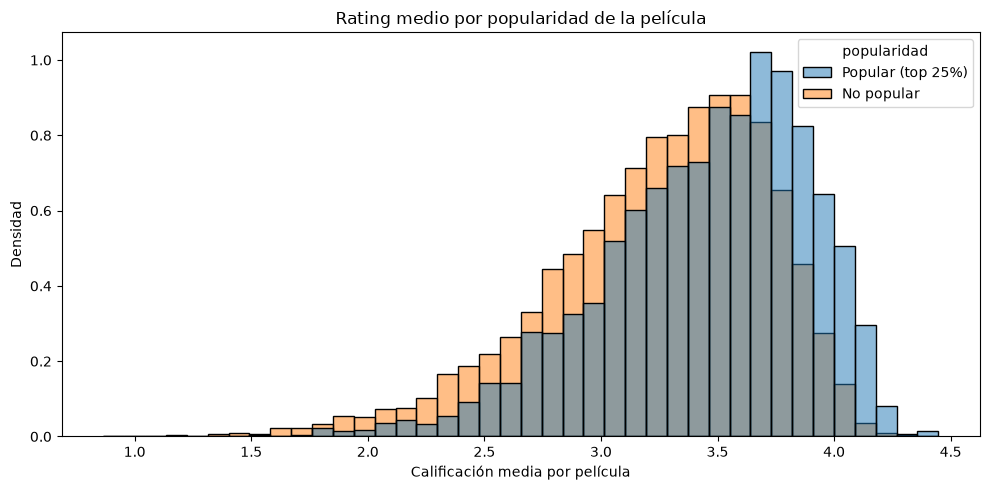

In [38]:
# Comparación popular vs no popular
rated_movies = movies[movies.rating_count >=100]\
                    .dropna(subset=["rating_mean", "rating_count"]).copy()
popular_threshold = rated_movies["rating_count"].quantile(0.75)
rated_movies["popularidad"] = np.where(
    rated_movies["rating_count"] >= popular_threshold,
    "Popular (top 25%)",
    "No popular",
)
popular = rated_movies.loc[rated_movies["popularidad"] == "Popular (top 25%)", "rating_mean"]
not_popular = rated_movies.loc[rated_movies["popularidad"] == "No popular", "rating_mean"]

mann_u, mann_p = stats.mannwhitneyu(popular, not_popular, alternative="two-sided", method="auto")
welch_t, welch_p = stats.ttest_ind(popular, not_popular, equal_var=False)
# Biserial de rango aproximado: 1 significa que popular siempre supera a no popular
rank_biserial = 2 * mann_u / (len(popular) * len(not_popular)) - 1

popularity_results = pd.DataFrame([
    {"prueba": "Mann-Whitney U", "estadístico": mann_u, "p_valor": mann_p, "decisión": "Rechazar H0" if mann_p < alpha else "No rechazar H0"},
    {"prueba": "Welch t (robustez)", "estadístico": welch_t, "p_valor": welch_p, "decisión": "Rechazar H0" if welch_p < alpha else "No rechazar H0"},
])
print(f"Umbral del percentil 75: {popular_threshold:,.2f} evaluaciones")
print("Resumen por popularidad:")
display(rated_movies.groupby("popularidad")["rating_mean"].agg(["count", "mean", "median", "std"]).round(4))
display(popularity_results.round(6))
print(f"Biserial de rango aproximado: {rank_biserial:.4f}")

sns.histplot(data=rated_movies, x="rating_mean", hue="popularidad", bins=40, stat="density", common_norm=False)
plt.title("Rating medio por popularidad de la película")
plt.xlabel("Calificación media por película")
plt.ylabel("Densidad")
plt.tight_layout()
plt.show()


#### Resultado y lectura

| Medida | No populares | Populares |
|---|---:|---:|
| n | 9,143 | 3,048 |
| Media de `rating_mean` | 3.2458 | 3.4464 |
| Mediana | 3.3182 | 3.5163 |
| Desviación estándar | 0.4795 | 0.4477 |

Las dos pruebas rechazan H0 con p-valores menores a 0.0001:

- Mann-Whitney U = 17,374,599.00.
- Welch t = 21.0437.

La popularidad se acompaña de una diferencia visible: el grupo popular presenta una media 0.2006 puntos mayor y una mediana 0.1981 puntos mayor que el grupo no popular. El biserial de rango aproximado es **0.2469**, una magnitud moderada que apoya una tendencia popular-hacia-calificaciones-más-altas.

**Interpretación y cautela.** El resultado no demuestra que ser popular haga subir la calificación. Puede haber factores comunes detrás de ambos atributos: gran expectativa, calidad percibida, antigüedad, mayor exposición o menor sesgo de selección. Además, el corte por percentil es una regla analítica y no una categoría intrínseca del catálogo.


### 3. Pruebas adicionales: ¿qué más cuenta la historia?

Además de género y popularidad, el conjunto permite investigar relaciones y diferencias con pruebas más específicas.

| Prueba | Pregunta que resuelve | Datos | Uso en este análisis |
|---|---|---|---|
| **Spearman** | ¿Votos y calificación media crecen conjuntamente de forma monotónica? | `rating_count`, `rating_mean` | La implementa sin asumir una relación lineal. |
| **Chi-cuadrado de independencia** | ¿La popularidad depende de la presencia de un género? | Género × popularidad | Se ejecuta género por género y con corrección de Bonferroni. |
| **Kruskal-Wallis o prueba de tendencia ordinal** | ¿Los rangos de calificación cambian al pasar por niveles de popularidad o antigüedad? | `rating_mean` y rangos de exposición | Complementa el contraste popular/no popular o compara más de dos bandas. |
| **Regresión ordinal o modelo mixto** | ¿Qué factores explican una calificación individual controlando usuario y película? | `rating`, `userId`, `movieId`, tiempo | Permite separar preferencias individuales de efectos de catálogo. |
| **Prueba temporal por cohortes** | ¿Cambia el patrón de calificaciones según año de estreno o periodo de evaluación? | `year` o `timestamp` | Permite estudiar deriva temporal y diferencias entre generaciones de películas. |

#### Spearman: volumen y calificación

En las **12,191 películas con al menos 100 votos**, Spearman obtuvo **rho = 0.1913** y p < 0.0001. La relación es positiva pero débil: las películas con más votos tienden a tener calificaciones medias ligeramente mayores, pero el volumen explica por sí solo una proporción pequeña de la variación.

#### Chi-cuadrado: popularidad asociada a géneros

Tras aplicar Bonferroni, aparecen asociaciones significativas para **12 géneros**: Action, Adventure, IMAX, Sci-Fi, Thriller, Documentary, Fantasy, Crime, Horror, Children, Mystery y Romance. Drama y Comedy sí tienen p-valores nominales menores que 0.05, pero dejan de ser significativos después de la corrección múltiple; Animation, Western, Musical y Film-Noir tampoco ofrecen evidencia significativa.

**Valor adicional.** Esta prueba muestra qué géneros tienen perfiles de popularidad distintos, pero no mide qué tan grande es esa asociación ni establece qué género “produce” popularidad.


In [39]:
# Prueba adicional: Spearman entre volumen de votos y rating medio
spearman_df = rated_movies[rated_movies["rating_count"] >= 100]
spearman_r, spearman_p = stats.spearmanr(
    spearman_df["rating_count"],
    spearman_df["rating_mean"],
)
print("Spearman formal (películas con al menos 100 votos):")
display(pd.DataFrame([{
    "prueba": "Spearman",
    "n": len(spearman_df),
    "rho": spearman_r,
    "p_valor": spearman_p,
    "decisión": "Rechazar H0" if spearman_p < alpha else "No rechazar H0",
}]).round(6))


Spearman formal (películas con al menos 100 votos):


,prueba,n,rho,p_valor,decisión
0,Spearman,12191,0.1913,0.0000,Rechazar H0


In [40]:
# Prueba adicional: chi-cuadrado popularidad × género
# Se evalúa género por género; 0.05/20 usa una aproximación conservadora de Bonferroni.
top_genres_for_test = genre_counts.nlargest(20, "count").index.tolist()
chi_rows = []
for genre_name in top_genres_for_test:
    presence = per_movie.drop_duplicates("movieId").merge(
        movie_genres[movie_genres["genre"] == genre_name][["movieId"]].assign(presencia=1),
        on="movieId",
        how="left",
    )
    presence["presencia"] = presence["presencia"].fillna(0)
    presence = presence.merge(rated_movies[["movieId", "popularidad"]], on="movieId", how="inner")
    contingency = pd.crosstab(presence["presencia"], presence["popularidad"])
    if contingency.shape == (2, 2):
        chi2, pvalue, dof, expected = stats.chi2_contingency(contingency, correction=False)
        chi_rows.append({
            "género": genre_name,
            "chi2": chi2,
            "gl": dof,
            "p_valor": pvalue,
            "p_bonferroni": min(1.0, pvalue * len(top_genres_for_test)),
            "significativo_bonferroni": pvalue * len(top_genres_for_test) < alpha,
        })

chi_df = pd.DataFrame(chi_rows)
print("Chi-cuadrado por género (popular vs no popular):")
display(chi_df.sort_values("p_bonferroni").round(6))


Chi-cuadrado por género (popular vs no popular):


,género,chi2,gl,p_valor,p_bonferroni,significativo_bonferroni
4,Action,286.4804,1,0.0000,0.0000,True
8,Adventure,232.3208,1,0.0000,0.0000,True
18,IMAX,210.7709,1,0.0000,0.0000,True
9,Sci-Fi,165.6011,1,0.0000,0.0000,True
2,Thriller,100.4837,1,0.0000,0.0000,True
5,Documentary,91.6613,1,0.0000,0.0000,True
13,Fantasy,57.0197,1,0.0000,0.0000,True
7,Crime,35.4864,1,0.0000,0.0000,True
6,Horror,21.8415,1,0.0000,0.0001,True
11,Children,20.5755,1,0.0000,0.0001,True


### 4. Conclusión integrada

La evidencia converge en un patrón: **las calificaciones medias no son homogéneas entre géneros ni entre niveles de popularidad**. Las mayores medias aparecen en Documentaries, Film-Noir e IMAX; las menores, en Horror, Sci-Fi y Action. Al comparar títulos populares y no populares, los populares promedian 3.4464 frente a 3.2458 y mantienen una mediana mayor.

El siguiente nivel de detalle viene de las comparaciones por pares y asociaciones adicionales:

- Tukey encuentra 141 pares significativos entre 171 posibles.
- Mann-Whitney y Welch coinciden en rechazar la igualdad entre popularidad.
- Spearman revela una relación positiva débil entre votos y calificación (`rho = 0.1913`).
- Chi-cuadrado muestra 12 géneros asociados significativamente con popularidad después de Bonferroni.

La lectura definitiva debe ser moderada. En bases de gran tamaño, la significancia es fácil de alcanzar; por eso se integran las medias, medianas, intervalos, proporción de variación y efectos de rango. Además, un género puede solaparse con otros, una calificación media puede ocultar diferencias entre usuarios y popularidad puede reflejar exposición en lugar de calidad. Las pruebas implementadas describen diferencias y asociaciones observables, pero no prueban causalidad.
